# Exploratory Data Analysis (EDA)

**Goal:** visualize and understand the data before modelling
**Dataset:** `Cleaned_Dataset.csv` (output of the pre-processing notebook)


### 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

### 2. Load Dataset

In [2]:
# load cleaned data
df = pd.read_csv(r"D:\OJT\Solar_Energy_Production_Analysis\data\Cleaned_Dataset.csv")
# observe few rows to make sure dataset successfully loaded
df.head()

,Project ID,Interconnection Date,Utility,City/Town,County,Zip,Division,Substation,Developer,Metering Method,Estimated PV System Size (kWdc),PV System Size (kWac),Estimated Annual PV Energy Production (kWh),Energy Storage System Size (kWac)
0,SDG-66301,12/29/2023,Con Ed,Richmond Hill,Queens,11418.0,CENY-BK,Brownsville_2,Kamtech Solar Solutions,NM,6.05,5.17,7100,NaN
1,SDG-66299,12/29/2023,Con Ed,Bronx,Bronx,10473.0,CENY-BX,Parkchester_2,Kamtech Solar Solutions,NM,6.74,5.76,7911,NaN
2,SDG-66288,12/29/2023,Con Ed,Brooklyn,Kings,11225.0,CENY-BK,Bensonhurst_2,SUNCO,NM,3.05,2.61,3585,NaN
3,SDG-66284,12/29/2023,Con Ed,Brooklyn,Kings,11236.0,CENY-BK,Bensonhurst_2,Kamtech Solar Solutions,NM,5.62,4.80,6592,NaN
4,SDG-66277,12/28/2023,Con Ed,Springfield Gardens,Queens,11413.0,CENY-Q,Jamaica,Kamtech Solar Solutions,NM,6.05,5.17,7100,NaN


### 3. Fix Zip Data Type and Identify Numerical / Categorical Columns

The CSV stores `Zip` as a number, so it is converted back to a 5-digit string (it is an identifier) before the columns are split by type.

In [3]:
# Convert Zip(num) to a 5-digit zero-padded string
df['Zip'] = df['Zip'].astype(str).str.zfill(5)

numeric_cols = df.select_dtypes(include = "number").columns.to_list()
categorical_cols = df.select_dtypes(include = "object").columns.to_list()

print("\n Numeric_columns: - \n", numeric_cols)
print("\n Categorical Columns: - \n", categorical_cols)


 Numeric_columns: - 
 ['Estimated PV System Size (kWdc)', 'PV System Size (kWac)', 'Estimated Annual PV Energy Production (kWh)', 'Energy Storage System Size (kWac)']

 Categorical Columns: - 
 ['Project ID', 'Interconnection Date', 'Utility', 'City/Town', 'County', 'Zip', 'Division', 'Substation', 'Developer', 'Metering Method']


### 4. Target Distribution: Estimated Annual PV Energy Production (kWh)

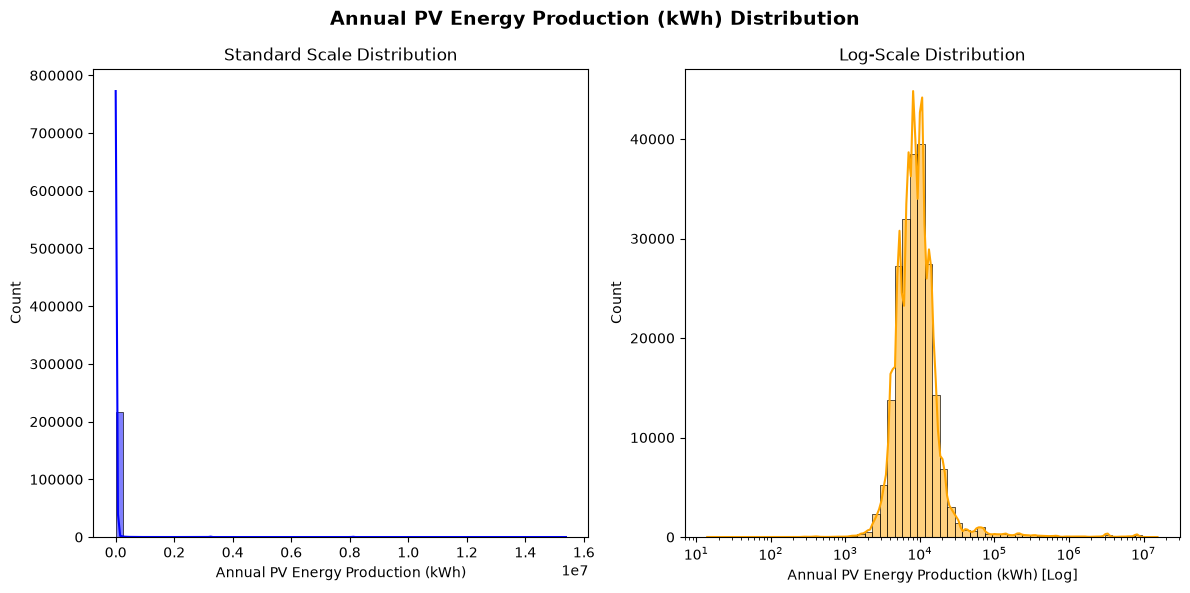

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# --- Plot 1: Standard Scale Distribution ---
sns.histplot(
    data=df, 
    x='Estimated Annual PV Energy Production (kWh)', 
    bins=60, 
    kde=True, 
    ax=axes[0],      
    color='blue'
)
axes[0].set_title('Standard Scale Distribution')
axes[0].set_xlabel('Annual PV Energy Production (kWh)')
axes[0].set_ylabel('Count')

# --- Plot 2: Log Scale Distribution (handles heavy right-skew) ---
sns.histplot(
    data=df, 
    x='Estimated Annual PV Energy Production (kWh)', 
    bins=60, 
    kde=True, 
    ax=axes[1],      
    color='orange',
    log_scale=True   
)
axes[1].set_title('Log-Scale Distribution')
axes[1].set_xlabel('Annual PV Energy Production (kWh) [Log]')
axes[1].set_ylabel('Count')

plt.suptitle('Annual PV Energy Production (kWh) Distribution', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

#### 4.1 Skewness check

In [5]:
print(df.select_dtypes(include="number").skew())

Estimated PV System Size (kWdc)                22.406607
PV System Size (kWac)                          22.323342
Estimated Annual PV Energy Production (kWh)    22.406607
Energy Storage System Size (kWac)              14.459803
dtype: float64


**Observation**
- The target and the size columns are strongly right-skewed (skewness ≈ 22). Therefore the **target** is modelled as `log1p(y)` (using `TransformedTargetRegressor` in model notebook).
- The skewness of the target and of `Estimated PV System Size (kWdc)` is identical (22.406607), which confirms that the target is simply proportional to `kWdc`. This is why the size columns are not used as inputs.
- The size columns are not model inputs, so they are not log-transformed.

### 5. Number of Projects by Utility Provider

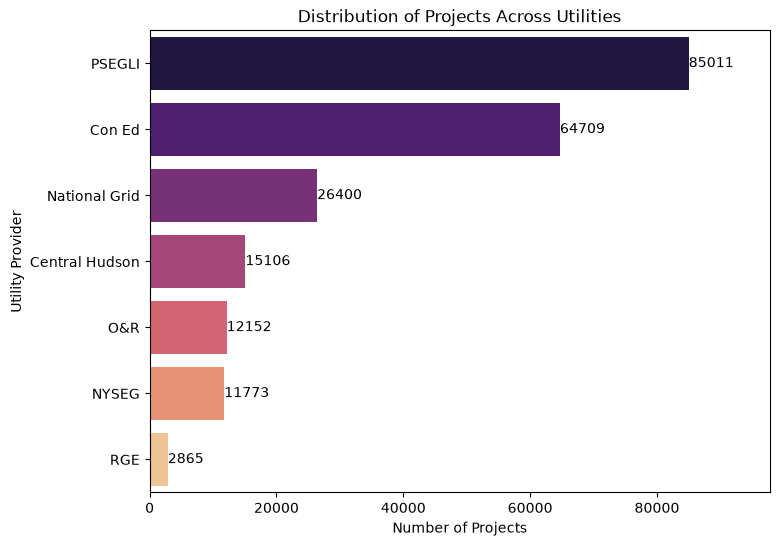

In [6]:
plt.figure(figsize=(8, 6))

ax = sns.countplot(
    data=df,
    y='Utility',
    order=df['Utility'].value_counts().index,
    palette='magma'
)

for container in ax.containers:
    ax.bar_label(container)

ax.set_xlim(0, df['Utility'].value_counts().max() * 1.15)

plt.title('Distribution of Projects Across Utilities')
plt.xlabel('Number of Projects')
plt.ylabel('Utility Provider')
plt.show()

**Observation**
- **PSEGLI** has the most projects (85,011), followed by **Con Ed** (64,709) and **National Grid** (26,400). Central Hudson (15,106), O&R (12,152) and NYSEG (11,773) follow.
- **RGE** has the fewest projects (2,865).
- This chart shows the number of projects, not total energy production.

### 6. Outlier Check (Box Plots)

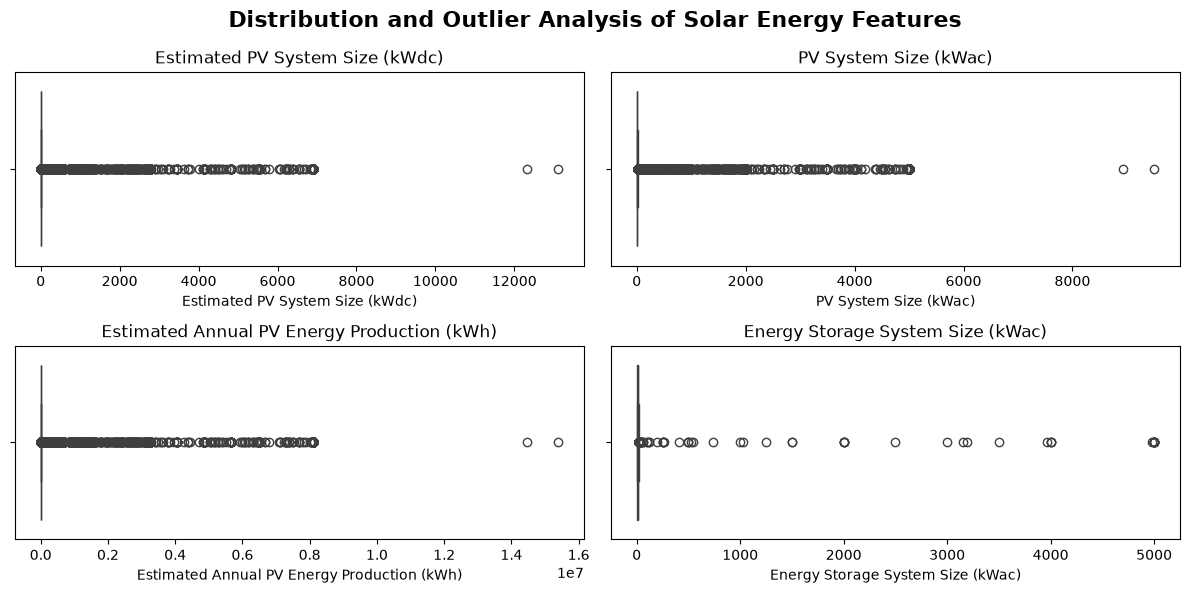

In [7]:
num_col = ['Estimated PV System Size (kWdc)', 'PV System Size (kWac)', 'Estimated Annual PV Energy Production (kWh)', 'Energy Storage System Size (kWac)']

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
axes = axes.flatten() # It converts the 2D(n-D array) axes array into a 1D array

for i, col in enumerate(num_col):
    sns.boxplot(
        data=df, 
        x=col,  # Pass column name as string
        ax=axes[i], 
    )
        
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
   
plt.suptitle('Distribution and Outlier Analysis of Solar Energy Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

**Observation**


### 7. Annual Production vs. PV System Size (kWdc, kWac) and Energy Storage

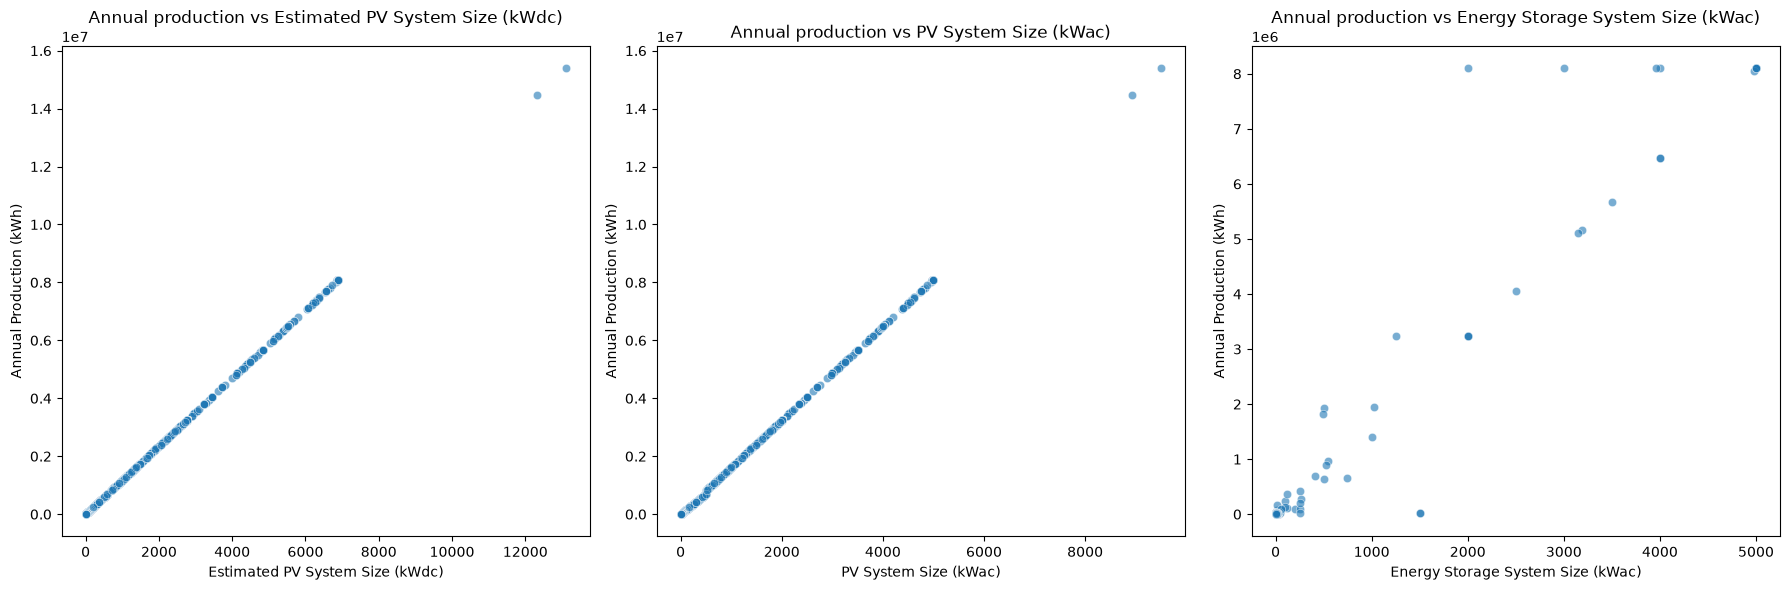

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

cols = [
    'Estimated PV System Size (kWdc)', 
    'PV System Size (kWac)', 
    'Energy Storage System Size (kWac)'
]

for i, col in enumerate(cols):
    sns.scatterplot(
        data=df, 
        x=col,  # Pass column name as string
        y='Estimated Annual PV Energy Production (kWh)', 
        ax=axes[i], 
        alpha=0.6  
    )
    
    axes[i].set_title(f'Annual production vs {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Annual Production (kWh)')
    
   

plt.tight_layout()
plt.show()

**Observation**
- Both DC and AC system sizes show a very strong, almost perfectly linear, positive relationship with **estimated annual energy production**.
- As PV system size increases, estimated annual energy production increases proportionally.
- **Energy Storage system size(kWac)** show a weak +ve correlation with target.

### 8. Geographic Distribution

#### 8.1 Top 10 Counties and Cities/Towns by Number of Solar Projects

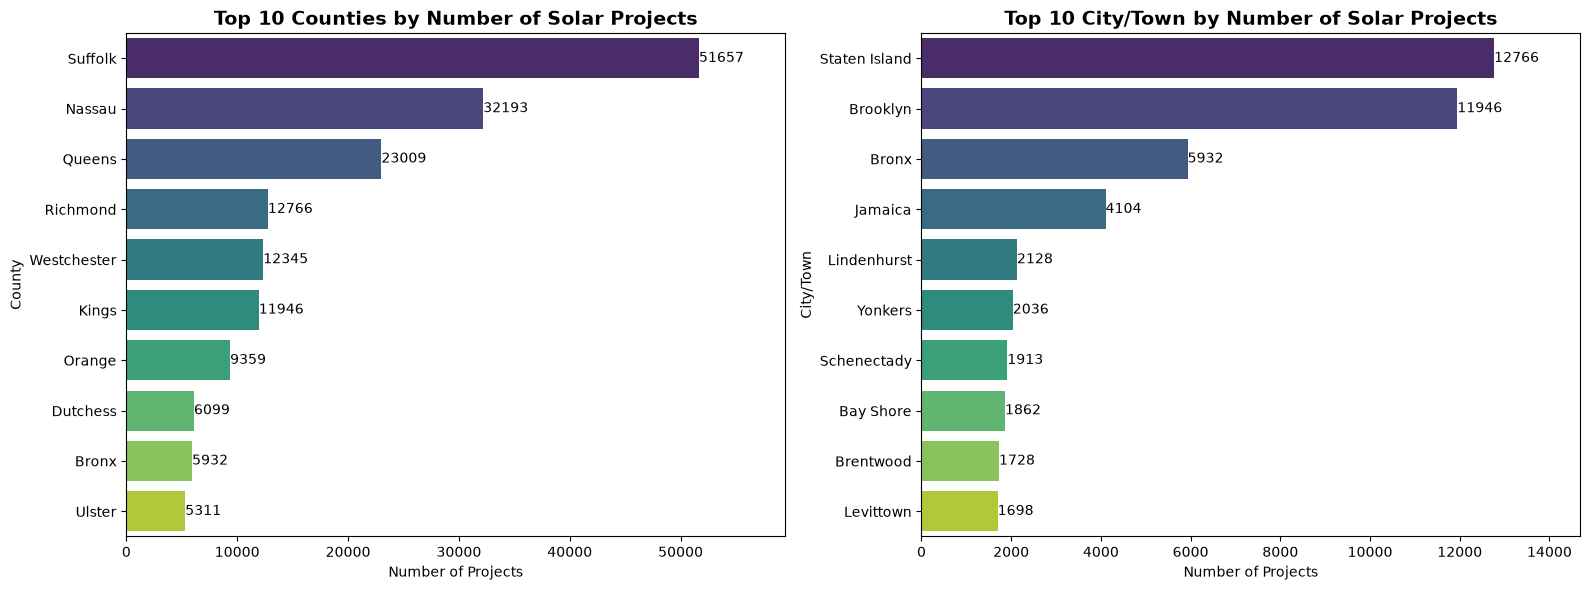

In [9]:
top_counties = df['County'].value_counts().head(10)
top_city_town = df['City/Town'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize = (16,6))

#-------Top 10 Counties-------
sns.barplot(
    x=top_counties.values, 
    y=top_counties.index, 
    palette='viridis',
    ax = axes[0]
)

for container in axes[0].containers:
    axes[0].bar_label(container)

axes[0].set_title('Top 10 Counties by Number of Solar Projects', fontweight='bold', fontsize=14)
axes[0].set_xlabel('Number of Projects')
axes[0].set_ylabel('County')
axes[0].set_xlim(0, top_counties.max() * 1.15)

#---------Top 10 City/Town--------
sns.barplot(
    x=top_city_town.values, 
    y=top_city_town.index, 
    palette='viridis',
    ax = axes[1]
)

for container in axes[1].containers:
    axes[1].bar_label(container)

axes[1].set_title('Top 10 City/Town by Number of Solar Projects', fontweight='bold', fontsize=14)
axes[1].set_xlabel('Number of Projects')
axes[1].set_ylabel('City/Town')
axes[1].set_xlim(0, top_city_town.max() * 1.15)

plt.tight_layout()
plt.show()

**Observation**
- **Highest Projects by County**: **Suffolk** has the highest number of solar projects, with **45,625** projects.
- **Highest Projects by City/Town**: **staten island** has the highest number of solar project, with **12,743** projects.

#### 8.2 Average Production Share by County and City/Town

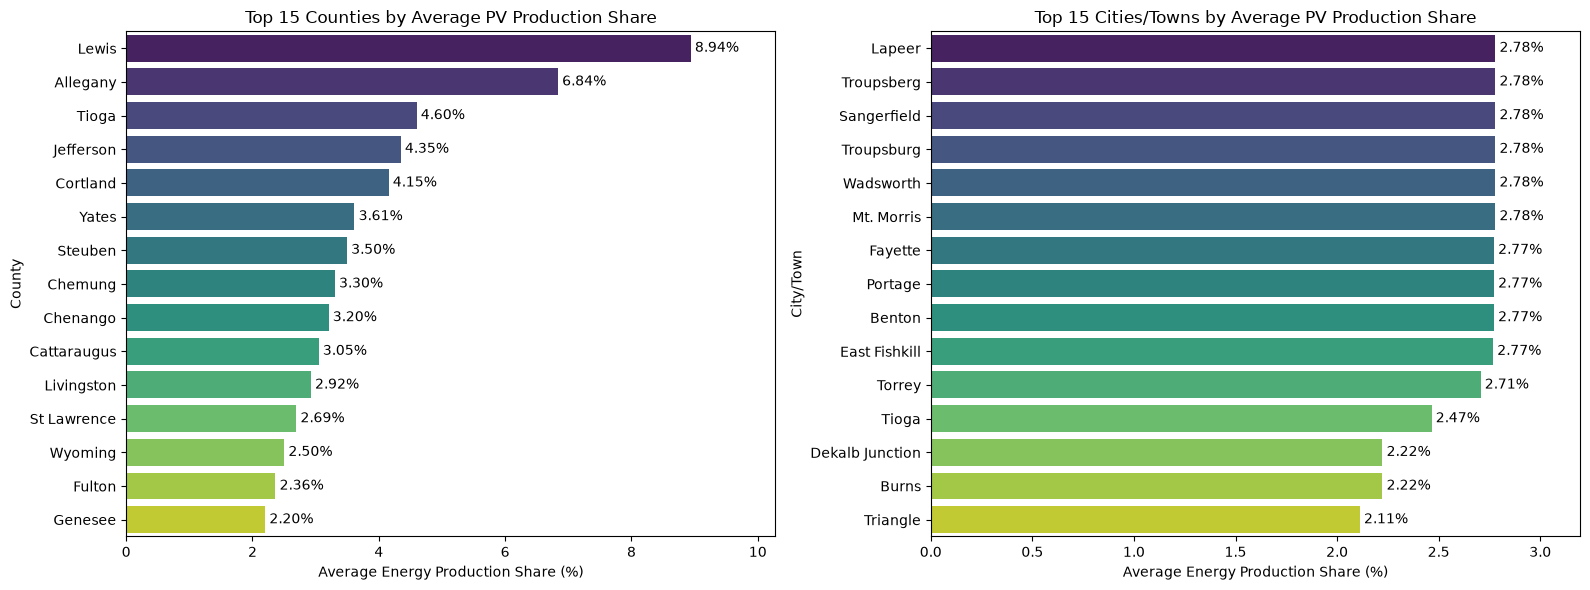

In [10]:
# Group by County and calculate average production share percentage
production_rate_by_county = (
    df.groupby('County')['Estimated Annual PV Energy Production (kWh)']
    .mean()
    .pipe(lambda x: x / x.sum() * 100)
    .sort_values(ascending=False)
    .head(15)
)

production_rate_by_city = (
    df.groupby('City/Town')['Estimated Annual PV Energy Production (kWh)']
    .mean()
    .pipe(lambda x: x / x.sum() * 100)
    .sort_values(ascending=False)
    .head(15)
)

fig, axs = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: County ---
sns.barplot(
    x=production_rate_by_county.values,
    y=production_rate_by_county.index,
    palette='viridis',
    ax=axs[0]
)

for container in axs[0].containers:
  axs[0].bar_label(container, fmt='%.2f%%', padding=3)

axs[0].set_xlim(0, production_rate_by_county.max() * 1.15)
axs[0].set_title('Top 15 Counties by Average PV Production Share')
axs[0].set_xlabel('Average Energy Production Share (%)')
axs[0].set_ylabel('County')

# --- Plot 2: City/Town ---

sns.barplot(
    x=production_rate_by_city.values,
    y=production_rate_by_city.index,
    palette='viridis',
    ax=axs[1],
)

for container in axs[1].containers:
  axs[1].bar_label(container, fmt='%.2f%%', padding=3)

axs[1].set_xlim(0, production_rate_by_city.max() * 1.15)
axs[1].set_title('Top 15 Cities/Towns by Average PV Production Share')
axs[1].set_xlabel('Average Energy Production Share (%)')
axs[1].set_ylabel('City/Town')

plt.tight_layout()
plt.show()

**Observation**
- **County level:** **Lewis** has the highest average PV production share (8.94%), followed by **Allegany** (6.84%) and **Tioga** (4.60%).
- **City/Town level:** the top places (Lapeer, Wadsworth, Sangerfield, Troupsburg, Mt. Morris, etc.) all have almost identical shares (~2.75%), which suggests they have very few projects each (probably one large project). Check project counts per city before drawing conclusions.
- *Share* = a group's mean production divided by the sum of all group means, so it compares average project size, not total production.
- `Troupsburg` and `Troupsberg` appear as separate towns in the plot above (the plot was made before the fix). The pre-processing notebook (section 10.2) now merges them; re-run it and this notebook to update the plot.

### 9. Project Trends by Interconnection Date

In [11]:
# Convert 'Interconnection Date' from string to datetime dtype
df['Interconnection Date'] = pd.to_datetime(
    df['Interconnection Date'], errors='coerce'
)

# Make sure changes successfully
print(df['Interconnection Date'].dtype)

# Extract Year and Month from Date
df['Year'] = df['Interconnection Date'].dt.year
df['Month'] = df['Interconnection Date'].dt.month

datetime64[us]


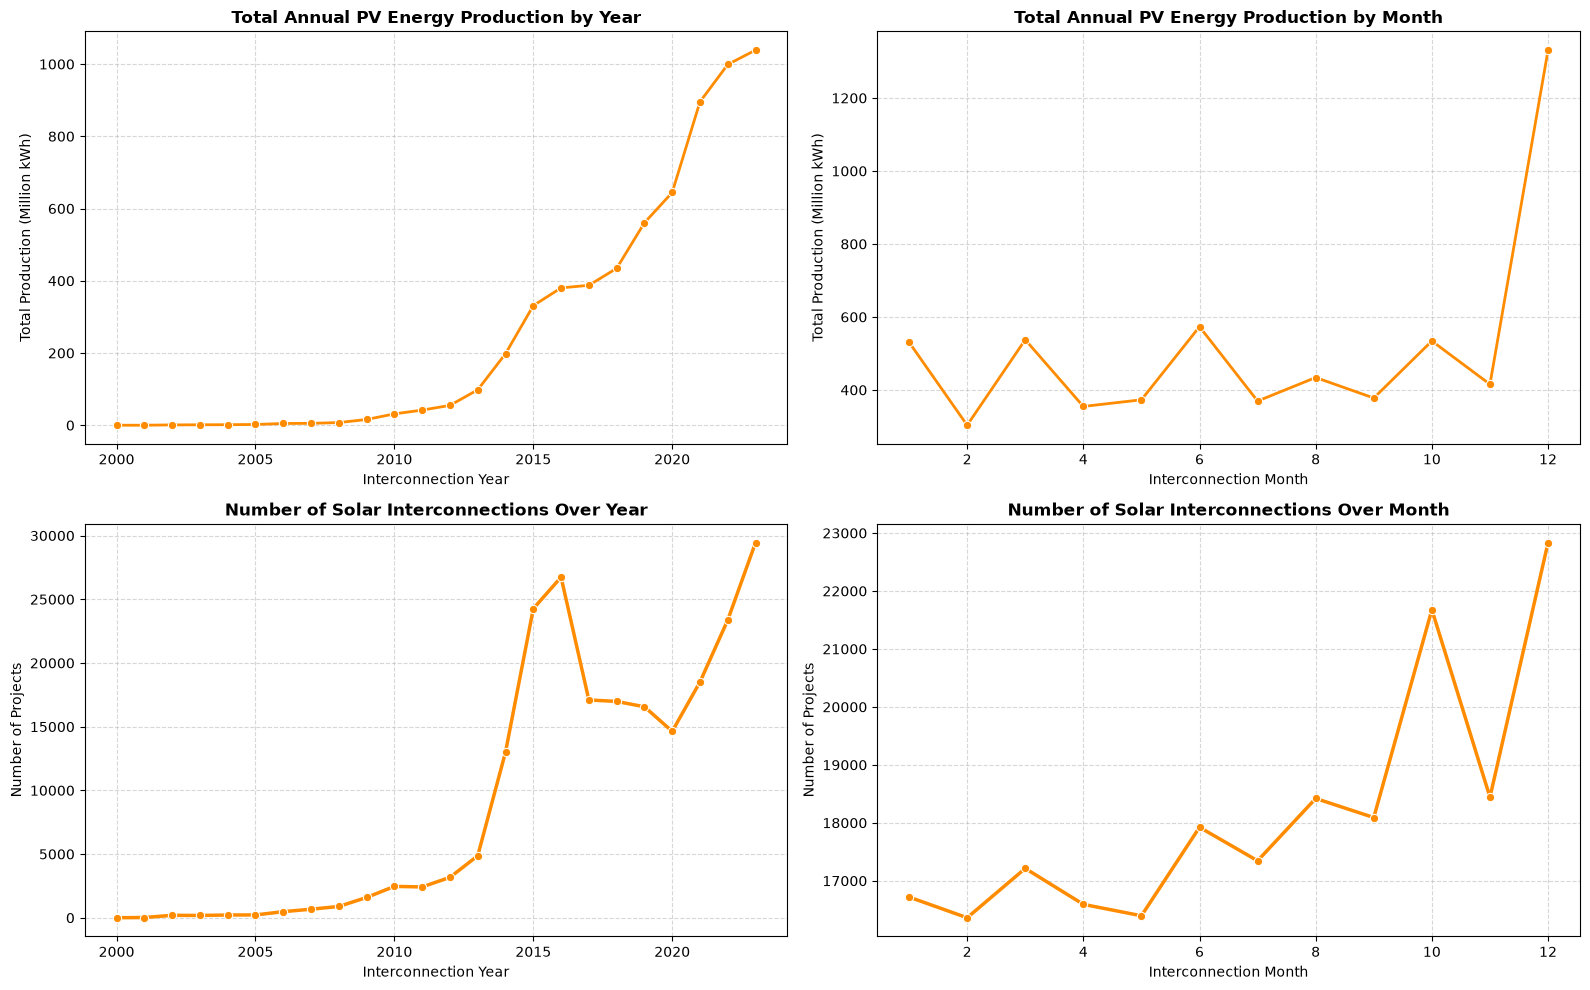

In [12]:
total_prod_by_year = (
    df.groupby('Year')['Estimated Annual PV Energy Production (kWh)'].sum()
    / 1e6
)

total_prod_by_month = (
    df.groupby('Month')['Estimated Annual PV Energy Production (kWh)'].sum()
    / 1e6
)

# Create a 2x2 subplot grid and flatten it for easy indexing
fig, axs = plt.subplots(2, 2, figsize=(16, 10))
axs = axs.flatten()

# --- Plot 1: Total Annual Production by Year ---
sns.lineplot(
    x=total_prod_by_year.index,
    y=total_prod_by_year.values,
    color='darkorange',
    marker='o',
    linewidth=2,
    ax=axs[0]
)
axs[0].set_title('Total Annual PV Energy Production by Year', fontweight='bold')
axs[0].set_xlabel('Interconnection Year')
axs[0].set_ylabel('Total Production (Million kWh)')
axs[0].grid(True, linestyle='--', alpha=0.5)

# --- Plot 2: Total Annual Production by Month ---
sns.lineplot(
    x=total_prod_by_month.index,
    y=total_prod_by_month.values,
    color='darkorange',
    marker='o',
    linewidth=2,
    ax=axs[1]    
)
axs[1].set_title('Total Annual PV Energy Production by Month', fontweight='bold')
axs[1].set_xlabel('Interconnection Month')
axs[1].set_ylabel('Total Production (Million kWh)')
axs[1].grid(True, linestyle='--', alpha=0.5)

# --- Plot 3: Number of Solar Interconnections Over Year ---
yearly_installations = df['Year'].value_counts().sort_index()

sns.lineplot(
    x=yearly_installations.index, 
    y=yearly_installations.values, 
    marker='o', 
    color='darkorange', 
    linewidth=2.5,
    ax=axs[2]
)
axs[2].set_title('Number of Solar Interconnections Over Year', fontweight='bold')
axs[2].set_xlabel('Interconnection Year')
axs[2].set_ylabel('Number of Projects')
axs[2].grid(True, linestyle='--', alpha=0.5)

# --- Plot 4: Number of Solar Interconnections Over Month ---
monthly_installations = df['Month'].value_counts().sort_index()

sns.lineplot(
    x=monthly_installations.index, 
    y=monthly_installations.values, 
    marker='o', 
    color='darkorange', 
    linewidth=2.5,
    ax=axs[3]
)
axs[3].set_title('Number of Solar Interconnections Over Month', fontweight='bold')
axs[3].set_xlabel('Interconnection Month')
axs[3].set_ylabel('Number of Projects')
axs[3].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Observation**
- **Production by year:** the total estimated annual production of projects interconnected each year was close to zero before about 2008, grew quickly from about 2013, and reached about 1,040 million kWh for 2023. (This is the estimated yearly output of each year's new projects, not measured generation.)
- **Production by month:** this plot groups projects by the *month of interconnection*, not by the month of generation, so it does not show seasonal solar output. December stands out clearly (~1,330 million kWh, far above the other months).
- **Interconnections by year:** projects peaked around 2016 (~26,800), fell to ~14,700 in 2020, and then rose again to a new high of ~29,500 in 2023.
- **Interconnections by month:** December (~22,800) and October (~21,700) have the most interconnections. This may reflect a year-end rush, but the data does not confirm the reason.

### 10. Correlation Between Numerical features

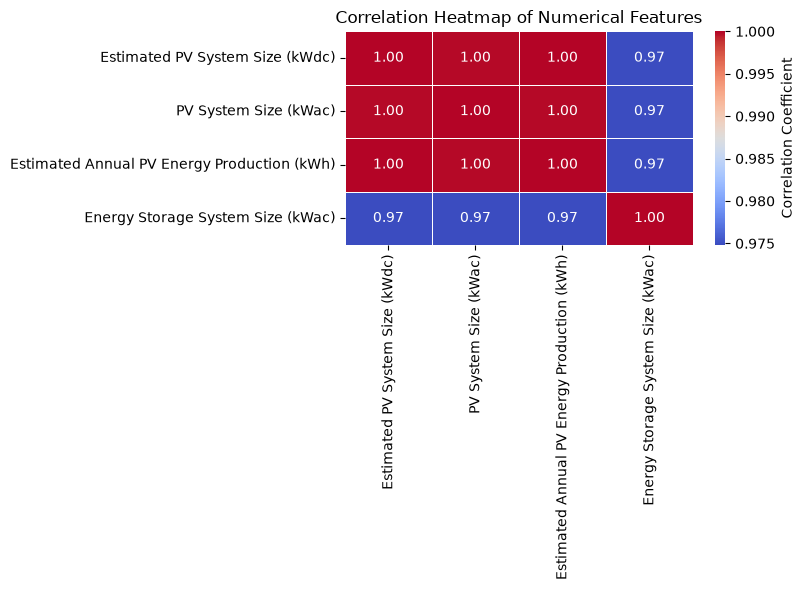

In [13]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df[numeric_cols].corr(), 
    annot=True, 
    cmap='coolwarm', 
    fmt='.2f', 
    linewidths=0.5,
    cbar_kws={'label': 'Correlation Coefficient'}
)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

**Observation**
- The correlation of `Estimated PV System Size (kWdc)` and `PV System Size (kWac)` with the target (`Estimated Annual PV Energy Production (kWh)`) rounds to 1.00, a (near-)perfect linear relationship. The two size columns are also almost perfectly correlated with each other, so they carry nearly the same information.
- `Energy Storage System Size (kWac)` has a correlation of 0.97 with the other three columns. This is calculated only on the ~4,090 projects with storage (pairwise), and is driven by project size, so it should not be read as a "weak" relationship.

### 11. Key Takeaways
1. The target is heavily right-skewed , so it is modelled as `log1p(y)`.
2. Annual production is almost a straight-line function of PV system size (correlation ≈ 1.00). A model that uses system size would be close to trivial, so the model notebook decides explicitly whether to include it.
3. Large projects are rare but real; they are kept and handled through the log transform.
4. `Energy Storage System Size (kWac)` is missing for ~98% of projects, so it is converted to a "has storage" flag. then Drop it.
5. Projects are concentrated in Long Island and New York City, and many cities/counties have only a few projects, so high-cardinality location columns are target-encoded rather than one-hot encoded.
6. Interconnections peak in December and October, and counts grew sharply after 2013, so year and month are useful date features.
7. Spelling variants in `City/Town` are merged in pre-processing ; Correct the some spelling mistkes in excel